# Assignment 6: Data Scraping
```
Course: ENV 700 - Environmental Data Exploration
Author: Student Name
Date: Fall 2026
```

This notebook accompanies the Python lessons on **Data Scraping**. We'll be scraping data from the North Carolina Department of Water Quality (NC DWQ). 

## 1. Setup
* Import packages: `requests`, `BeautifulSoup` (from `bs4`), `pandas` (as `pd`), `seaborn` (as `sns`) and any other packages you wish to use. 
* Set your Seaborn theme's style, context, and any runtime configurations you wish

In [77]:
#Import packages
import requests
from bs4 import BeautifulSoup
import pandas as pd
import seaborn as sns
import calendar
import time
from itertools import product

#Set Seaborn theme
sns.set_theme(
    style='whitegrid',
    context='notebook',
    palette= "colorblind", #INCLUDE
    font_scale = 0.8, #INCLUDE
    rc={
        "axes.titlesize": 15, #INCLUDE
        "font.family": "sans-serif", #INCLUDE
        "figure.facecolor": "#F1F1F1",
        "axes.facecolor": "#F1F1F1",
        "axes.grid": False,
        "xtick.bottom": True,
        "xtick.color": "black",
        "ytick.left": True,
        "ytick.color": "black",
        "axes.edgecolor": "black",
        "axes.linewidth": 1.0,
 })


## 2. Scraping Water Supply Data 
We will be scraping data from the NC DEQs Local Water Supply Planning website, specifically the Durham's 2025 Municipal Local Water Supply Plan (LWSP): 
 * Navigate to https://www.ncwater.org/WUDC/app/LWSP/search.php
 * Set the year to 2025
 * Scroll down and select the LWSP link next to Durham Municipality. 
 * Note the web address: <https://www.ncwater.org/WUDC/app/LWSP/report.php?pwsid=03-32-010&year=2025>

---
### 2.1 Retrieve the website and parse it using BeautifulSoup

In [78]:
# 2.1 Retrieve the website and parse it using BeautifulSoup
url = "https://www.ncwater.org/WUDC/app/LWSP/report.php?pwsid=03-32-010&year=2025"

response = requests.get(url)
response.raise_for_status()

webpage = BeautifulSoup(response.text, "html.parser")
type(webpage)

if webpage.title: 
    print(webpage.title.get_text(strip=True))
else: print("No page title")

DWR :: Local Water Supply Planning


### 2.2 The data we want to collect are listed below:

* From the **1. System Information** section:
    - Water system name
    - Contact Person
    - Ownership
 
* From the **3. Water Supply Sources** section:
    - Maximum Day Use (MGD) - for each month

In the code chunk below scrape these values, assigning them to four separate variables.  
>HINT: The first value should be "`Durham`", the second "`Kieu Tran`", the third "`Municipality`", and the last should be a vector of 12 numeric values (represented as strings)".

In [79]:
# 2.2 Scrape the data into variables
system_nodes = webpage.select("td tr:nth-child(1) td:nth-child(2)")
water_system = system_nodes[0].get_text(strip=True)
print(water_system)

contact_nodes = webpage.select("div+ table tr:nth-child(4) td:nth-child(2)")
contact_person = contact_nodes[0].get_text(strip=True)
print(contact_person)

ownership_nodes = webpage.select("tr:nth-child(2) td:nth-child(4)")
ownership = ownership_nodes[0].get_text(strip=True)
print(ownership)

max_nodes = webpage.select(
    "th~ td+ td"
)

max_withdrawals = [node.get_text(strip=True) for node in max_nodes]
print(max_withdrawals)

Durham
Kieu Tran
Municipality
['40.2400', '37.3800', '37.9100', '33.8100', '36.8400', '36.9000', '36.5300', '38.0400', '33.8000', '37.9500', '35.2000', '32.2000']


### 2.3 Construct a dataframe from the scraped data
Convert your scraped data into a dataframe. 
* This dataframe should have a column for each of the 4 variables scraped and a row for the month corresponding to the withdrawal data. 
* Note that you won't likely be able to scrape max water usage data in chronological order.
* Include columns for the month and year the data were collected. 
* Sort the data on year and month.
* Construct a datetime column from the year and month, assuming the day of the month will be the first. 

>🔥**TIP**: : To construct a list from a repeated set of values, use this approach:
>```python
>years_x6 = [2025] * 6
>print(years_x6)
>```

>🔥**TIP**: To construct a datetime column when you just the year and month, you can use the following:
>```python
>df['Date'] = pd.to_datetime({
>    "year": df['Year'],
>    "month": df['Month'],
>    "day": 1
>})
>```

In [80]:
# 2.3 Construct the dataframe from scraped data
month_order = [1, 5, 9, 2, 6, 10, 3, 7, 11, 4, 8, 12]

df_durham_LWSP = pd.DataFrame({
    "Month" : month_order,
    "Year" : 2025,
    "Maximum_Daily_Use" : pd.to_numeric(max_withdrawals),
})

df_durham_LWSP = df_durham_LWSP.assign(
    Water_System_Name = water_system,
    Contact_Person = contact_person,
    Ownership = ownership,
    Date=lambda d: pd.to_datetime(dict(year=d["Year"], month=d["Month"], day=1)),
).sort_values("Date")

df_durham_LWSP

,Month,Year,Maximum_Daily_Use,Water_System_Name,Contact_Person,Ownership,Date
0,1,2025,40.24,Durham,Kieu Tran,Municipality,2025-01-01
3,2,2025,33.81,Durham,Kieu Tran,Municipality,2025-02-01
6,3,2025,36.53,Durham,Kieu Tran,Municipality,2025-03-01
9,4,2025,37.95,Durham,Kieu Tran,Municipality,2025-04-01
1,5,2025,37.38,Durham,Kieu Tran,Municipality,2025-05-01
4,6,2025,36.84,Durham,Kieu Tran,Municipality,2025-06-01
7,7,2025,38.04,Durham,Kieu Tran,Municipality,2025-07-01
10,8,2025,35.20,Durham,Kieu Tran,Municipality,2025-08-01
2,9,2025,37.91,Durham,Kieu Tran,Municipality,2025-09-01
5,10,2025,36.90,Durham,Kieu Tran,Municipality,2025-10-01


### 2.4 Plot the data
* Create a line plot of the maximum daily withdrawals across the months for 2024
* Label the x-axis with month names or abbreviated month names. (Note, you may have to do some more wrangling...)

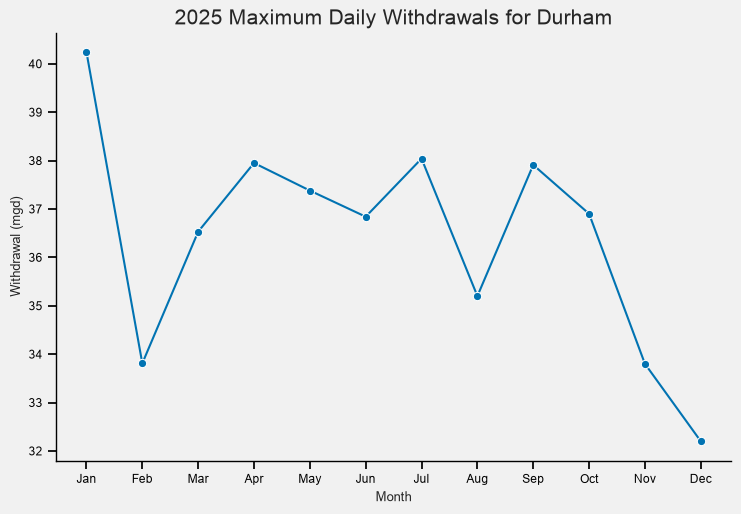

In [81]:
# 2.4 Plot the data
#wrangle 
df_durham_LWSP['month_abb'] = pd.Categorical(
    values = df_durham_LWSP['Date'].dt.month_name().str[:3],
    categories = calendar.month_abbr[1:])

g = sns.relplot(
    data = df_durham_LWSP,
    x = 'month_abb',
    y = 'Maximum_Daily_Use',
    kind = 'line',
    marker = 'o',
    aspect = 1.5
);

g.set(
    title=f"2025 Maximum Daily Withdrawals for {water_system}",
    xlabel="Month",
    ylabel="Withdrawal (mgd)",
);

## 3. Automating the Scraping Process
### 3.1 Construct the scraping function
Note that the PWSID and the year appear in the web address for the page we scraped. Construct a function with two inputs, "PWSID" and "year", that:
  - Creates a URL pointing to the LWSP for that PWSID for the given year
  - Creates a website object and scrapes the data from that object (just as you did above)
  - Constructs a dataframe from the scraped data, mostly as you did above, but includes the PWSID and year provided as function inputs in the dataframe. 
  - Returns the dataframe as the function's output

In [82]:
# 3.1 Create a scraping function
#create vars for year and facility id
the_year = 2020
Facility_Id = ''

def scrape_it(Facility_Id, the_year, pause=0):
    """Scrape the max daily withdrawals for one NC facility and year"""
    #construct URL and fetch website
    url = f"https://www.ncwater.org/WUDC/app/LWSP/report.php?pwsid={Facility_Id}&year={the_year}"
    response = requests.get(url)
    response.raise_for_status()
    webpage = BeautifulSoup(response.text, 'html.parser')

    #extract data from website 
    water_system = webpage.select_one("td tr:nth-child(1) td:nth-child(2)").get_text(strip=True)
    contact_person = webpage.select_one("div+ table tr:nth-child(4) td:nth-child(2)").get_text(strip=True)
    ownership = webpage.select_one("tr:nth-child(2) td:nth-child(4)").get_text(strip=True)
    max_nodes = webpage.select("th~ td+ td")
    max_withdrawals = [x.get_text(strip=True) for x in webpage.select("th~ td+ td")]

    #wrangle into a dataframe
    month_order = [1, 5, 9, 2, 6, 10, 3, 7, 11, 4, 8, 12]

    df = pd.DataFrame({
        "Month" : month_order,
        "Year" : the_year,
        "Maximum_Daily_Use" : pd.to_numeric(max_withdrawals),
    })

    df = df.assign(
        Water_System_Name = water_system,
        Contact_Person = contact_person,
        Ownership = ownership,
        Date=lambda d: pd.to_datetime(dict(year=d["Year"], month=d["Month"], day=1)),
    ).sort_values("Date").reset_index(drop = True)

    #pause before proceeding
    if pause: time.sleep(pause)

    #return dataframe
    return df

### 3.2 Fetch and plot data for Durham (PWSID=`03-32-010`) in 2020
* Use the function above to extract and plot max daily withdrawals for Durham (PWSID=`03-32-010`) for each month in 2020.
* Reveal the structure of your dataframe using the `info()` function. 
* Then create plot your data in a line plot as above: Max Usage by Month.

In [111]:
# 3.2.1 Scrape data for 03-32-010 in 2020 & display its structure
the_year = 2020
Facility_Id = '03-32-010'

df_durham_2020 = scrape_it(Facility_Id,the_year)

df_durham_2020.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Month              12 non-null     int64         
 1   Year               12 non-null     int64         
 2   Maximum_Daily_Use  12 non-null     float64       
 3   Water_System_Name  12 non-null     str           
 4   Contact_Person     12 non-null     str           
 5   Ownership          12 non-null     str           
 6   Date               12 non-null     datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 804.0 bytes


In [112]:
df_durham_2020

,Month,Year,Maximum_Daily_Use,Water_System_Name,Contact_Person,Ownership,Date
0,1,2020,36.01,Durham,Kieu Tran,Municipality,2020-01-01
1,2,2020,32.05,Durham,Kieu Tran,Municipality,2020-02-01
2,3,2020,37.29,Durham,Kieu Tran,Municipality,2020-03-01
3,4,2020,32.37,Durham,Kieu Tran,Municipality,2020-04-01
4,5,2020,36.98,Durham,Kieu Tran,Municipality,2020-05-01
5,6,2020,40.61,Durham,Kieu Tran,Municipality,2020-06-01
6,7,2020,43.63,Durham,Kieu Tran,Municipality,2020-07-01
7,8,2020,41.93,Durham,Kieu Tran,Municipality,2020-08-01
8,9,2020,41.69,Durham,Kieu Tran,Municipality,2020-09-01
9,10,2020,40.56,Durham,Kieu Tran,Municipality,2020-10-01


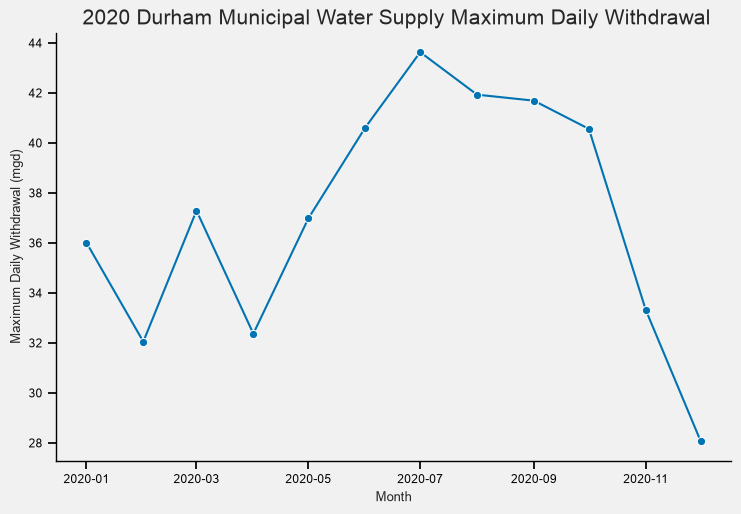

In [113]:
# 3.2.2 Plot the data
t = sns.relplot(
    data = df_durham_2020,
    x = 'Date',
    y = 'Maximum_Daily_Use',
    kind = 'line',
    marker = 'o',
    aspect = 1.5
)

t.set(
    xlabel = ("Month"),
    ylabel = "Maximum Daily Withdrawal (mgd)",
    title = f" {the_year} Durham Municipal Water Supply Maximum Daily Withdrawal"
)


### 3.3 Fetch and plot data for Cary (PWSID=`03-92-020`) in 2020

In [86]:
# 3.3.1 Fetch and plot data for Cary (PWSID=`03-92-020`) in 2020
Facility_Id = "03-92-020"
the_year = 2020

df_cary_2020 = scrape_it(Facility_Id, the_year)

df_cary_2020


,Month,Year,Maximum_Daily_Use,Water_System_Name,Contact_Person,Ownership,Date
0,1,2020,21.95,Cary,Jamie Revels,Municipality,2020-01-01
1,2,2020,17.70,Cary,Jamie Revels,Municipality,2020-02-01
2,3,2020,20.56,Cary,Jamie Revels,Municipality,2020-03-01
3,4,2020,19.32,Cary,Jamie Revels,Municipality,2020-04-01
4,5,2020,23.22,Cary,Jamie Revels,Municipality,2020-05-01
5,6,2020,26.19,Cary,Jamie Revels,Municipality,2020-06-01
6,7,2020,28.01,Cary,Jamie Revels,Municipality,2020-07-01
7,8,2020,25.40,Cary,Jamie Revels,Municipality,2020-08-01
8,9,2020,25.49,Cary,Jamie Revels,Municipality,2020-09-01
9,10,2020,23.60,Cary,Jamie Revels,Municipality,2020-10-01


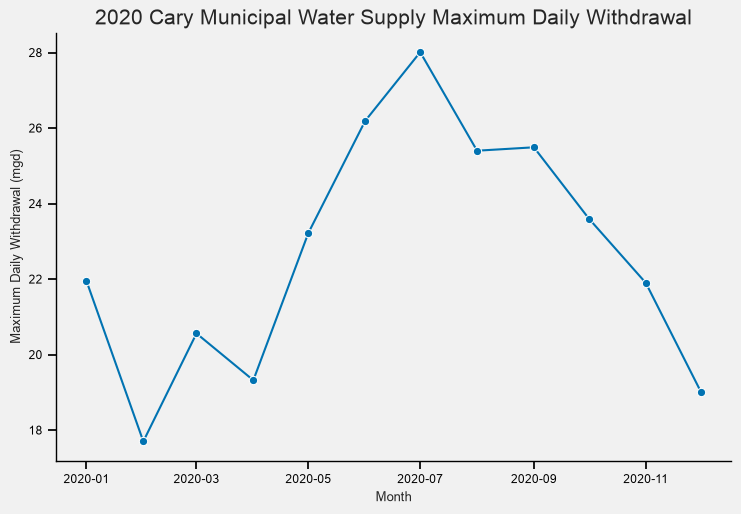

In [87]:
# 3.3.2 Plot the Cary data
x = sns.relplot(
    data = df_cary_2020,
    x = 'Date',
    y = 'Maximum_Daily_Use',
    kind = 'line',
    marker = 'o',
    aspect = 1.5
)

x.set(
    xlabel = ("Month"),
    ylabel = "Maximum Daily Withdrawal (mgd)",
    title = f"{the_year} Cary Municipal Water Supply Maximum Daily Withdrawal"
)


### 3.4 Examine monthy max discharge from 2020-2025
* Use list comprehension (or other methods) to produce a list of dataframes, one for each year in 2020 to 2025
* Concatenate these dataframes into a single one including data for all years
* Create a line plot of max monthly discharge across the full timespan (x-axis labels do not have to be months)

In [114]:
# 3.4.1 Generate a list of the dataframes
#set years and facility to scrape
the_years = range (2020,2026)
#03-92-020
#03-32-010

my_facility = "03-92-020"

#use list comprehension to capture result of applying the function to our range of years
the_dfs = [scrape_it(my_facility, year, pause=1) for year in the_years]

# 3.4.2 Combine them into a single dataframe
the_df = pd.concat(the_dfs, ignore_index=True)

Text(0.5, 0.96, '2020-2025')

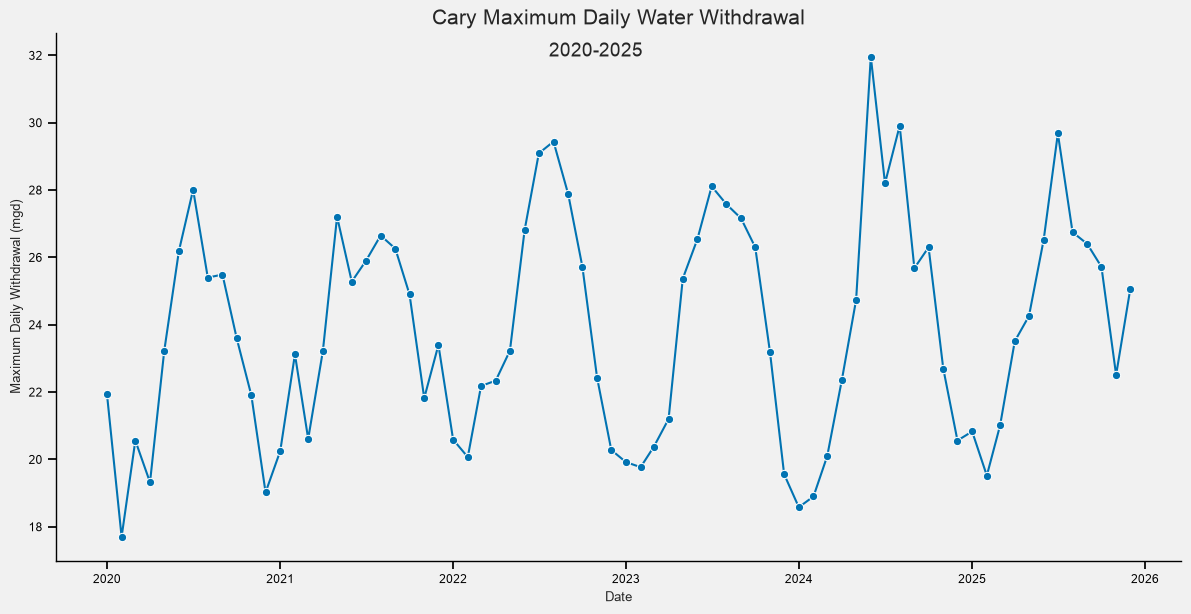

In [115]:
# 3.4.3 Plot
#extract values for plotting
the_facility = the_df.loc[0, 'Water_System_Name']
start_date = the_df['Date'].min()
end_date = the_df['Date'].max()

g = sns.relplot(
    data = the_df,
    x = "Date",
    y = "Maximum_Daily_Use",
    kind = 'line',
    marker = 'o',
    aspect = 2,
    height = 6
)

g.set(
    xlabel = "Date",
    ylabel = "Maximum Daily Withdrawal (mgd)",
    title = "Cary Maximum Daily Water Withdrawal"
)

g.figure.suptitle(
    f"{start_date.year}-{end_date.year}",
    fontsize = 14,
    y = 0.96
)